# PyPSA-Sudan → PyPSA-Earth: the evidence handover

**Status: prepared inputs and tested interfaces, not a newly solved national model.**

We are adopting the Zambia-style organisation: a Sudan evidence/configuration
layer on top of the standard national PyPSA-Earth workflow, plus a complementary
OnSSET electrification analysis. We do not need to reproduce every earlier
prototype inside PyPSA-Earth.

The initial national configuration uses Sudan, full-year 2022, ten spatial
clusters and three-hour chronological averages. Ten clusters are not ten states
or ten settlement zones. OnSSET's access focus remains Northern, River Nile,
Khartoum, Gezira, White Nile and Sennar.

Read [the integration guide](README.md) for WSL commands and the full evidence map.
This notebook can be rerun without downloading data or solving a network.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
HERE = Path.cwd()
if not (HERE / "generated").exists():
    HERE = HERE / "integration" / "pypsa_earth"
assert (HERE / "generated").exists(), "Run from this notebook's folder or repository root"
manifest = json.loads((HERE / "generated/evidence_manifest.json").read_text())
validation = json.loads((HERE / "validation/validation.json").read_text())
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
display(pd.DataFrame([
    ["National engine", "PyPSA-Earth in WSL", "Configuration + dry-run passed"],
    ["Demand", "Existing synthetic profile, calibrated annual total", "Enabled"],
    ["Plant corrections", "2019 inventory + dated 2012 coordinates", "Candidates only, disabled"],
    ["Recovery evidence", "Dated 2024 status and qualitative reports", "Not yet applied to assets"],
    ["Settlement electrification", "DRE evidence + OnSSET", "Separate complementary branch"],
    ["National solve", "New Earth workflow", "Not performed"],
], columns=["Layer", "Input / method", "Status"]))

,Layer,Input / method,Status
0,National engine,PyPSA-Earth in WSL,Configuration + dry-run passed
1,Demand,"Existing synthetic profile, calibrated annual ...",Enabled
2,Plant corrections,2019 inventory + dated 2012 coordinates,"Candidates only, disabled"
3,Recovery evidence,Dated 2024 status and qualitative reports,Not yet applied to assets
4,Settlement electrification,DRE evidence + OnSSET,Separate complementary branch
5,National solve,New Earth workflow,Not performed


## 1. The demand that actually enters the model

The source statistic is 13,261 GWh of end-use consumption (including an UNSD
estimate). The initial sent-out boundary also includes 3,652 GWh of aggregate
technical/nontechnical losses. These losses must not be added a second time.

The hourly shape is synthetic. It has been shifted from local UTC+2 to UTC as a
periodic annual template. `source: gegis` in the YAML selects the standard file
reader; it does not make this a GEGIS forecast.

The 882 GWh import benchmark is **not yet an import generator or border link**
in the new Earth model. This is a remaining baseline calibration task.

,Quantity,GWh
0,End use,13261
1,Aggregate losses,3652
2,Sent-out requirement,16913
3,Net generation benchmark,16031
4,Imports benchmark,882


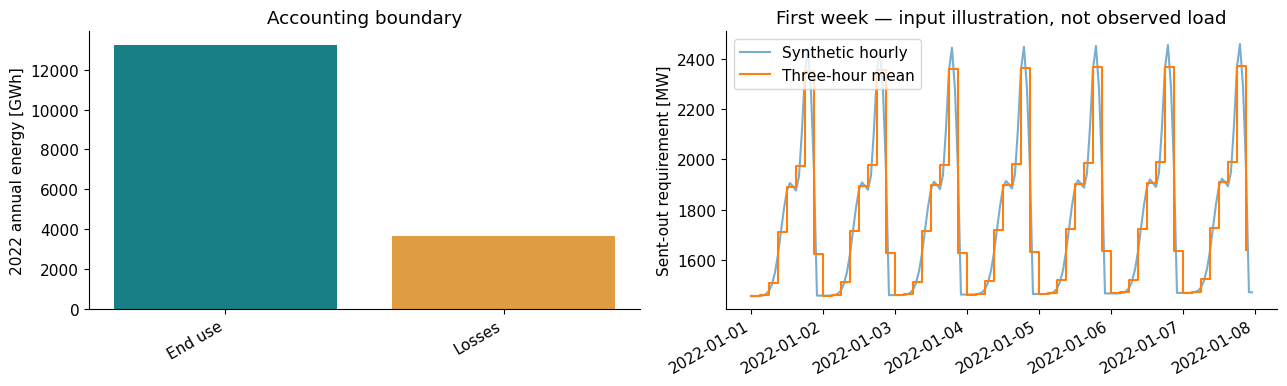

In [2]:
d = pd.read_csv(HERE / "generated/demand_accounting.csv", parse_dates=["time_UTC"]).set_index("time_UTC")
display(pd.DataFrame({
    "Quantity": ["End use", "Aggregate losses", "Sent-out requirement", "Net generation benchmark", "Imports benchmark"],
    "GWh": [13261, 3652, 16913, 16031, 882],
}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(["End use", "Losses"], [13261, 3652], color=["#187f85", "#df9c40"])
axes[0].set_ylabel("2022 annual energy [GWh]")
axes[0].set_title("Accounting boundary")
week = d.sent_out_requirement_MW.iloc[:168]
axes[1].plot(week.index, week, alpha=.6, label="Synthetic hourly")
three = week.resample("3h").mean()
axes[1].step(three.index, three, where="post", label="Three-hour mean")
axes[1].set_ylabel("Sent-out requirement [MW]")
axes[1].set_title("First week — input illustration, not observed load")
axes[1].legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 2. Plant evidence: useful, but not a complete 2022 fleet

The crosswalk preserves all 32 inventory rows, including planned entries.
Eleven entries can be linked explicitly to coordinates in the older engineering
report. Planned-only projects are excluded from the Earth-format candidate file.

**The candidate file is disabled.** Historical nameplate MW, national net MW,
reported available MW and future project MW are different quantities.
Garri 4's provisional fuel-carrier mapping and hydro reservoir classifications
also require review. Earth retains its default fleet until corrections are reconciled.
The displayed locations are dated report coordinates, not newly surveyed sites.

,Rows
integration_status,
candidate_only_reconcile_2022_net_capacity_and_identity,11
exclude_planned_not_verified_commissioned,12
review_missing_coordinates,9


,asset_name,installed_capacity_MW,latitude,longitude,coordinate_record_id,source_id,pdf_page
0,Merowe,1250.0,18.67,32.06,M-HP,R19,49
1,Kosti,500.0,13.16,32.66,Kos-ST,R19,49
2,Garri 1 and 2,469.0,16.12,32.69,G1_B1-2-CCGT2+1,R19,49
3,Garri 4,110.0,16.12,32.69,G4_U1-2-ST,R19,49
4,Mahmoud Sharif steam,380.0,15.65,32.56,KN_3-4-ST,R19,49
5,Mahmoud Sharif gas,150.0,15.65,32.56,KN_0-GT,R19,49
6,Roseires,280.0,11.80,34.39,Ros-HP,R19,49
8,Jabal Awlia,30.4,15.24,32.49,Jeb-HP,R19,49
9,Sinnar,15.0,13.55,33.64,Sen-HP,R19,49
10,Khashm El Girba,17.8,14.93,35.91,KhE-HP,R19,49


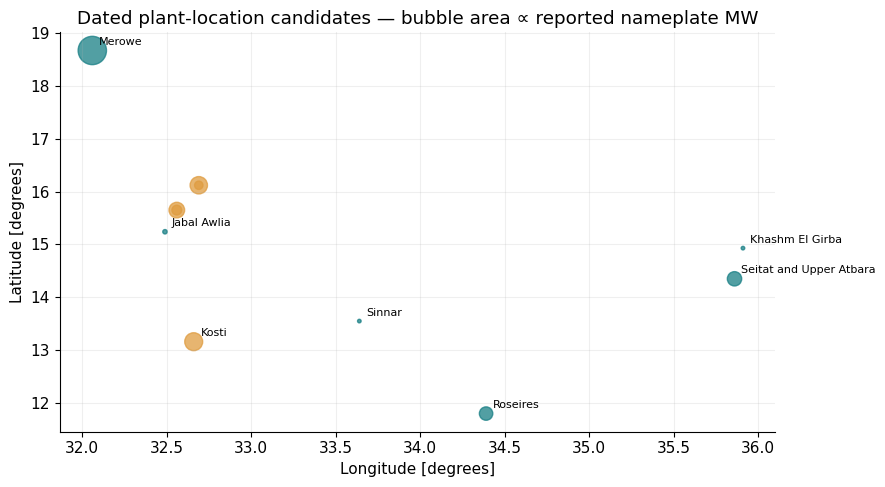

In [3]:
plants = pd.read_csv(HERE / "generated/plant_evidence_crosswalk.csv")
display(plants.groupby("integration_status").size().rename("Rows").to_frame())
located = plants.dropna(subset=["latitude", "longitude"])
display(located[["asset_name", "installed_capacity_MW", "latitude", "longitude",
                 "coordinate_record_id", "source_id", "pdf_page"]])
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(located.longitude, located.latitude,
           s=located.installed_capacity_MW.clip(lower=20) / 3,
           c=located.technology.eq("Hydro").map({True: "#187f85", False: "#df9c40"}),
           alpha=.75)
for row in located.itertuples():
    if row.technology == "Hydro" or row.asset_name == "Kosti":
        ax.annotate(row.asset_name, (row.longitude, row.latitude),
                    xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="Longitude [degrees]", ylabel="Latitude [degrees]",
       title="Dated plant-location candidates — bubble area ∝ reported nameplate MW")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 3. How post-conflict evidence will enter

| Evidence | Model treatment | What it cannot establish |
|---|---|---|
| Fuel-limited plant | Available fuel/dispatch constraint in a dated scenario | Destroyed capacity or repair bill |
| Reported plant shutdown | Scenario availability with documented cause | A measured year-round outage probability |
| Network separation | Explicit outage of mapped lines/transformers | Which asset failed without topology matching |
| Rehabilitation option | Defined restored capacity, cost and lifetime | The same thing as standard new-line expansion |
| DRE security category | Historical exposure/context | Current damage, access safety or a financial risk probability |
| Local equipment quotes | Documented cost components after harmonisation | Utility-scale turnkey costs in the same price year |

The three agreed recovery conditions remain limited, targeted and broad
restoration. We first need a common baseline. Keep assumptions explicit; do not
convert each report statement into another elaborate scenario.

Standard Earth expansion does not automatically optimize rehabilitation.
If rehabilitation choices are fixed outside the optimization, call them
**recovery scenarios**, rather than claiming the optimizer selected repairs.

## 4. What has actually passed

In [4]:
display(pd.Series(validation["input_checks"], name="Passed").to_frame())
display(pd.Series({k: validation[k] for k in [
    "demand_GWh", "snapshots_after_aggregation", "duration_hours",
    "candidate_plants_enabled", "snakemake_dry_run_exit_code",
    "era5_cutout_present", "national_solve_performed",
]}, name="Result").to_frame())
display(pd.Series(validation["software"], name="Installed version").to_frame())
assert validation["snakemake_dry_run_exit_code"] == 0
assert validation["national_solve_performed"] is False

,Passed
native_demand_reader,True
native_candidate_plant_reader,True
native_country_conversion,True
native_three_hour_aggregation,True
energy_and_all_duration_weights_preserved,True
tutorial_overrides_removed,True
projection_database_works,True


,Result
demand_GWh,16913.0
snapshots_after_aggregation,2920
duration_hours,8760.0
candidate_plants_enabled,False
snakemake_dry_run_exit_code,0
era5_cutout_present,False
national_solve_performed,False


,Installed version
pypsa,0.30.3
snakemake,7.32.4
atlite,0.4.1
pandas,2.3.1


## 5. The next concrete work

1. Configure Copernicus access privately in WSL and obtain the full 2022 ERA5
   cutout; standard geography and resource data must also be retrieved.
2. Build the Earth network, inspect its actual buses/lines and reconcile the
   plant fleet, hydro and 882 GWh import boundary.
3. Run and check the fixed-fleet baseline against the national statistics.
4. Add the three recovery conditions with traceable asset availability and
   rehabilitation costs; enable generation/storage/transmission investments as
   appropriate for that experiment.
5. Run complementary OnSSET access cases and present both branches in the main
   research notebook.

**Do not interpret a successful dry-run as a validated dispatch result.**
The full execution commands and evidence provenance are in [README.md](README.md)
and [the manifest](generated/evidence_manifest.json).

The former regional joint optimization and settlement-screen notebooks remain
supporting prototypes. Their results have not become outputs of this new Earth
configuration merely by copying evidence.